In [18]:
import json
import math
import tkinter as tk
from tkinter import messagebox, ttk

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib.colors import ListedColormap
from mpl_toolkits.mplot3d import Axes3D

import manim as mn
from manim import *

plt.style.use('style.mplstyle')

In [19]:
config.media_width = "75%"
config.verbosity = "WARNING"
config.background_color = BLUE_A
Text.set_default(color=BLACK, stroke_color=BLACK)
MathTex.set_default(color=BLACK, stroke_color=BLACK)

In [20]:
power = 85
base_attack = 105
defense = 78
level = 50

attack_evs = 0
total_evs = 66

In [21]:
def calc_attack(attack_evs, base_attack, atk_mult=1):
    return math.floor((base_attack + attack_evs + 20) * atk_mult)

In [22]:
def damage(attack_evs, base_attack=base_attack, atk_mult=1, power=100, defense=150, level=50, bonus=[1]):
    calculated_attack = calc_attack(attack_evs, base_attack, atk_mult)

    raw_damage = math.floor(((( ( (2 * level / 5) + 2) * power * ( (calculated_attack) / defense) ) / 50) + 2 ) * 0.85)
    raw_damage_unrounded = ((( ( (2 * level / 5) + 2) * power * ( (calculated_attack) / defense) ) / 50) + 2 ) * 0.85

    for b in bonus:
        raw_damage = round(raw_damage * b)
        raw_damage_unrounded = raw_damage_unrounded * b

    return raw_damage, raw_damage_unrounded

def damage_percent(attack_evs, base_attack=base_attack, power=100, total_evs=66, defense=150, health=100, level=50, bonus=[1], def_mult=1):
    if (attack_evs) > total_evs:  # Constraint check
        print("EV distribution exceeds total EV limit.")
        return None, None  # Invalid solution
    
    raw_damage, raw_damage_unrounded = damage(attack_evs, base_attack, atk_mult=1.2, power=power, defense=defense, level=level, bonus=bonus)

    return raw_damage / health * 100, raw_damage

Text(0, 0.5, 'Attack Value')

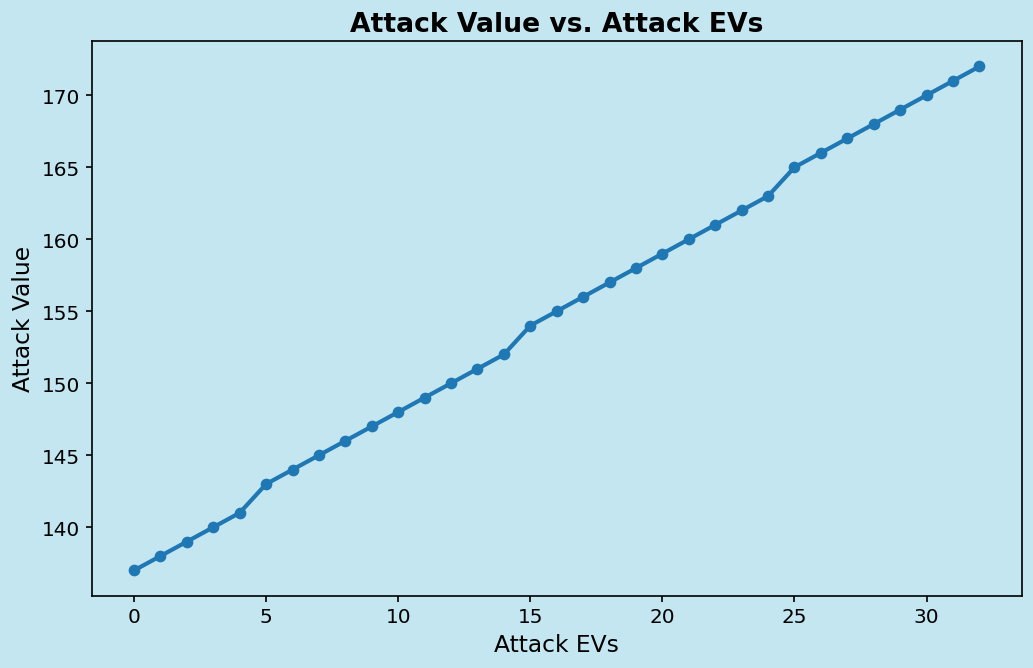

In [ ]:
attack_evs_range = range(0, 33)
attack_values = [calc_attack(ev, base_attack=105, atk_mult=1.1) for ev in attack_evs_range]

plt.plot(attack_evs_range, attack_values, marker='o')
plt.title('Attack Value vs. Attack EVs')
plt.xlabel('Attack EVs')
plt.ylabel('Attack Value')

Text(0, 0.5, 'Attack Value')

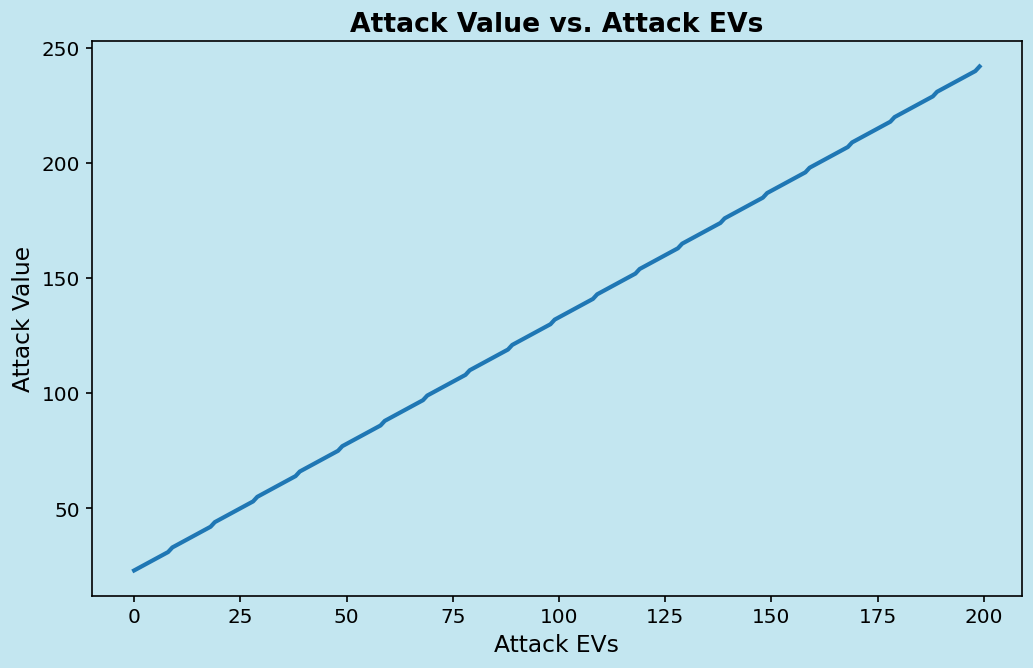

In [29]:
fake_attack_evs = range(0, 200)
attack_values = [calc_attack(ev, base_attack=1, atk_mult=1.1) for ev in fake_attack_evs]

plt.plot(fake_attack_evs, attack_values)
plt.title('Attack Value vs. Attack EVs')
plt.xlabel('Attack EVs')
plt.ylabel('Attack Value')

In [30]:
#find each attack ev pair that increases by more than 1 attack value
for i in range(len(attack_values) - 1):
    if attack_values[i + 1] - attack_values[i] > 1:
        print(f"Attack EVs: {fake_attack_evs[i]} -> {fake_attack_evs[i + 1]}, Attack Value: {attack_values[i]} -> {attack_values[i + 1]}")

Attack EVs: 8 -> 9, Attack Value: 31 -> 33
Attack EVs: 18 -> 19, Attack Value: 42 -> 44
Attack EVs: 28 -> 29, Attack Value: 53 -> 55
Attack EVs: 38 -> 39, Attack Value: 64 -> 66
Attack EVs: 48 -> 49, Attack Value: 75 -> 77
Attack EVs: 58 -> 59, Attack Value: 86 -> 88
Attack EVs: 68 -> 69, Attack Value: 97 -> 99
Attack EVs: 78 -> 79, Attack Value: 108 -> 110
Attack EVs: 88 -> 89, Attack Value: 119 -> 121
Attack EVs: 98 -> 99, Attack Value: 130 -> 132
Attack EVs: 108 -> 109, Attack Value: 141 -> 143
Attack EVs: 118 -> 119, Attack Value: 152 -> 154
Attack EVs: 128 -> 129, Attack Value: 163 -> 165
Attack EVs: 138 -> 139, Attack Value: 174 -> 176
Attack EVs: 148 -> 149, Attack Value: 185 -> 187
Attack EVs: 158 -> 159, Attack Value: 196 -> 198
Attack EVs: 168 -> 169, Attack Value: 207 -> 209
Attack EVs: 178 -> 179, Attack Value: 218 -> 220
Attack EVs: 188 -> 189, Attack Value: 229 -> 231
Attack EVs: 198 -> 199, Attack Value: 240 -> 242


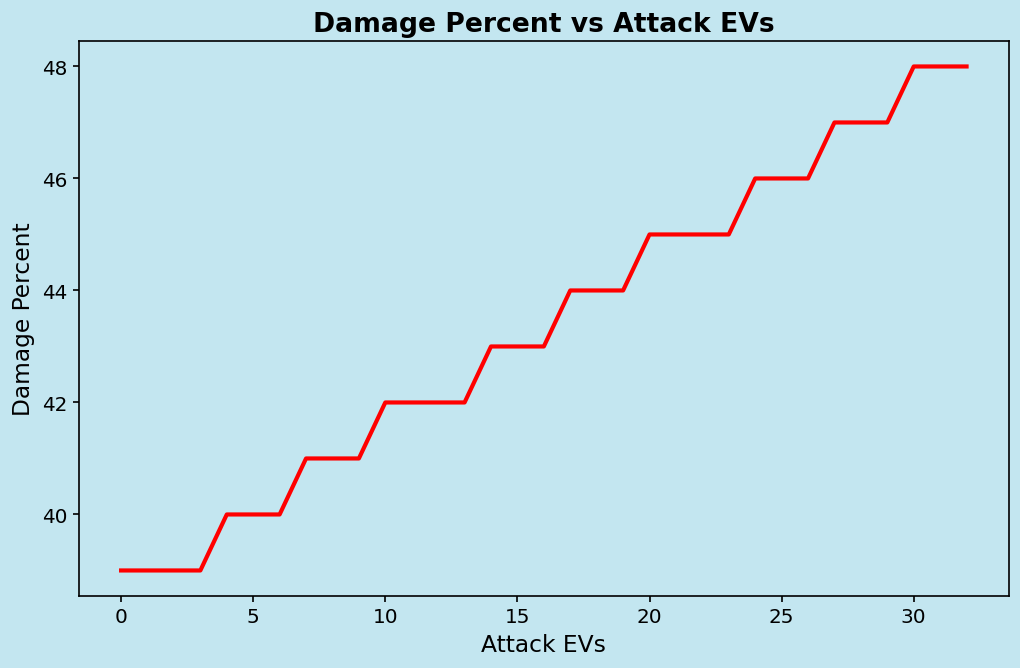

In [24]:
# Fix health_evs and vary defense_evs
attack_evs_range = range(0, 33)
damage_percent_values = [damage_percent(attack_evs, base_attack=base_attack, power=100, total_evs=total_evs, defense=150, health=100, level=50, bonus=[1])[0] for attack_evs in attack_evs_range]

# Plot the curve
plt.plot(attack_evs_range, damage_percent_values, color='red')
plt.xlabel('Attack EVs')
plt.ylabel('Damage Percent')
plt.title(f'Damage Percent vs Attack EVs')
plt.show()